# 01 · Data Engineering & Representation (Member 1)

**Big Data mini-project: distributed LSH for near-duplicate search on arXiv abstracts**

| Step | Output | Used for |
|---|---|---|
| 1. Ingestion | raw JSON converted once to Parquet | Slide 2, report (data ingestion) |
| 2. Cleaning | normalized abstracts + data-quality counts | report |
| 3. Shingling + vectors | k-shingles → binary HashingTF vectors (Parquet) | Members 2 and 3 |
| 4. Partitioning / caching | small benchmark | report (optimization) |
| 5. Choice of k and hash size | shingling analysis | report |
| 6. MinHash math demo | Jaccard = collision probability | seminar |
| 7. Slide 2 stats + hand-off | `slide2_stats.json`, schema | Slide 2 |

Set the knobs in the config cell, then **Runtime → Run all**.
Once `K`, `NUM_FEATURES` and `SEED` are shared with the team, keep them fixed so everyone's results are comparable.

## 0. Setup and configuration

In [1]:
!pip install -q pyspark kagglehub

In [2]:
import os, time, json, random, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pyspark import StorageLevel
from pyspark.sql import SparkSession, DataFrame, functions as F, types as T
from pyspark.ml.feature import NGram, HashingTF

# ----------------------------- knobs ----------------------------------------
SAMPLE_N      = 0           # tier size; 0 = full corpus (try 500_000 first as a smoke test)
K             = 3           # word-shingle size
NUM_FEATURES  = 1 << 18     # HashingTF dimension
MIN_CHARS     = 100         # drop abstracts shorter than this (after cleaning)
DROP_EXACT    = True        # remove byte-identical cleaned abstracts
INJECT_FRAC   = 0.01        # fraction of rows cloned as synthetic near-duplicates (0 = off)
DUP_DROP_MAX  = 0.30
SEED          = 36
PARTITIONS    = 128         # full corpus shuffles ~10 GB of vectors; 32 would spill to disk
# -----------------------------------------------------------------------------

WORK        = "/kaggle/temp/lsh"   # scratch space, not saved as output
RAW_PARQUET = f"{WORK}/raw_parquet"
TIER_NAME   = "full" if SAMPLE_N <= 0 else f"n{SAMPLE_N}"
OUT_DIR     = f"{WORK}/processed/arxiv_{TIER_NAME}_k{K}"
os.makedirs(WORK, exist_ok=True)
os.makedirs("/kaggle/temp/spark", exist_ok=True)

# NOTE: if a Spark session already exists in this runtime, these settings are
# ignored; restart the runtime if you change them.
spark = (SparkSession.builder.master("local[*]").appName("LSH-Member1")
         .config("spark.driver.memory", "20g")              # Kaggle CPU has ~29 GB RAM
         .config("spark.local.dir", "/kaggle/temp/spark")   # shuffle spill goes here
         .config("spark.sql.shuffle.partitions", PARTITIONS)
         .config("spark.sql.parquet.compression.codec", "snappy")
         .getOrCreate())
print("Spark", spark.version, "| cores:", spark.sparkContext.defaultParallelism)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/02 13:40:53 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/11/02 13:40:53 WARN SparkConf: Note that spark.local.dir will be overridden by the value set by the cluster manager (via SPARK_LOCAL_DIRS in standalone/kubernetes and LOCAL_DIRS in YARN).


Spark 4.0.4 | cores: 4


## 1. Download and ingest

Reading the 4 GB+ JSON with schema inference costs a full extra pass, and the `versions` / `authors_parsed` columns are
nested and never used. We therefore:

1. declare an **explicit schema** with only the columns we need,
2. convert once to **Parquet** (columnar, compressed, splittable) and use Parquet for everything afterwards.

In [3]:
import kagglehub

# path = kagglehub.dataset_download("Cornell-University/arxiv")
path = "/kaggle/input/datasets/Cornell-University/arxiv"
JSON_PATH = os.path.join(path, "arxiv-metadata-oai-snapshot.json")
raw_size_gb = os.path.getsize(JSON_PATH) / 1e9
print("Path to dataset files:", path)
print(f"Raw JSON size on disk: {raw_size_gb:.2f} GB")

Path to dataset files: /kaggle/input/datasets/Cornell-University/arxiv
Raw JSON size on disk: 5.67 GB


In [4]:
RAW_SCHEMA = T.StructType([
    T.StructField("id", T.StringType()),
    T.StructField("title", T.StringType()),
    T.StructField("abstract", T.StringType()),
    T.StructField("categories", T.StringType()),
    T.StructField("update_date", T.StringType()),
])

def dir_size_mb(p):
    return sum(os.path.getsize(os.path.join(dp, f))
               for dp, _, fs in os.walk(p) for f in fs) / 1e6

ingest_secs = None
if not os.path.exists(RAW_PARQUET):
    t0 = time.perf_counter()
    (spark.read.schema(RAW_SCHEMA).json(JSON_PATH)
          .withColumn("primary_category", F.split(F.col("categories"), " ")[0])
          .repartition(PARTITIONS)
          .write.mode("overwrite").parquet(RAW_PARQUET))
    ingest_secs = time.perf_counter() - t0
    print(f"JSON -> Parquet conversion: {ingest_secs:.1f} s")

raw = spark.read.parquet(RAW_PARQUET)
t0 = time.perf_counter()
n_raw = raw.count()
parquet_count_secs = time.perf_counter() - t0
raw_parquet_mb = dir_size_mb(RAW_PARQUET)
print(f"Rows: {n_raw:,} | Parquet size: {raw_parquet_mb:,.0f} MB | full count from Parquet: {parquet_count_secs:.1f} s")
raw.printSchema()
raw.select("id", "primary_category", "update_date").show(5, truncate=False)

JSON -> Parquet conversion: 98.2 s
Rows: 3,233,620 | Parquet size: 2,177 MB | full count from Parquet: 0.9 s
root
 |-- id: string (nullable = true)
 |-- title: string (nullable = true)
 |-- abstract: string (nullable = true)
 |-- categories: string (nullable = true)
 |-- update_date: string (nullable = true)
 |-- primary_category: string (nullable = true)

+---------+----------------+-----------+
|id       |primary_category|update_date|
+---------+----------------+-----------+
|0808.2944|math.FA         |2008-11-21 |
|0806.1332|gr-qc           |2008-11-26 |
|0805.2167|cond-mat.str-el |2009-11-13 |
|0704.3237|math-ph         |2007-05-23 |
|0803.3048|nucl-th         |2008-03-21 |
+---------+----------------+-----------+
only showing top 5 rows


## 2. Cleaning and normalization

Pipeline: lowercase → strip inline LaTeX (`$...$`) and leftover `\commands` → remove punctuation → collapse whitespace.
Then drop null / very short abstracts and arXiv "withdrawn" stubs, and (optionally) exact duplicates.
The counts below go straight into the report's data-quality table.

In [5]:
WITHDRAWN_RE = r"^.{0,200}(has been|was|is being) withdrawn"

def clean_text_col(c):
    x = F.lower(c)
    x = F.regexp_replace(x, r"\$[^$]*\$", " ")      # inline LaTeX
    x = F.regexp_replace(x, r"\\[a-z]+", " ")        # leftover \commands
    x = F.regexp_replace(x, r"[^a-z0-9\s]", " ")     # punctuation / symbols
    x = F.regexp_replace(x, r"\s+", " ")
    return F.trim(x)

tmp = raw.withColumn("clean_text", clean_text_col(F.col("abstract")))

quality = (tmp.agg(
    F.count("*").alias("raw_rows"),
    F.sum(F.col("abstract").isNull().cast("int")).alias("null_abstract"),
    F.sum((F.length("clean_text") < MIN_CHARS).cast("int")).alias("too_short"),
    F.sum(F.col("clean_text").rlike(WITHDRAWN_RE).cast("int")).alias("withdrawn"),
).collect()[0].asDict())

cleaned = (tmp.filter(F.col("clean_text").isNotNull())
              .filter(F.length("clean_text") >= MIN_CHARS)
              .filter(~F.col("clean_text").rlike(WITHDRAWN_RE))
              .select("id", "primary_category", "clean_text"))
n_clean = cleaned.count()

if DROP_EXACT:
    # deterministic: keep the smallest id for each distinct text
    deduped = (cleaned.groupBy("clean_text")
                      .agg(F.min(F.struct("id", "primary_category")).alias("r"))
                      .select("r.id", "r.primary_category", "clean_text"))
else:
    deduped = cleaned

# Materialize each dedup step once: otherwise every later count / sample / write recomputes the shuffle.
TEXT_DEDUP_PARQUET = f"{WORK}/text_dedup_parquet"
deduped.write.mode("overwrite").parquet(TEXT_DEDUP_PARQUET)
deduped = spark.read.parquet(TEXT_DEDUP_PARQUET)
n_text_dedup = deduped.count()

# ids must be unique: Member 2's join filters on A.id < B.id.
# Keep one row per id, chosen deterministically so reruns give the same data.
deduped = (deduped.groupBy("id")
                  .agg(F.min(F.struct("primary_category", "clean_text")).alias("r"))
                  .select("id", "r.primary_category", "r.clean_text"))

DEDUP_PARQUET = f"{WORK}/dedup_parquet"
deduped.write.mode("overwrite").parquet(DEDUP_PARQUET)
deduped = spark.read.parquet(DEDUP_PARQUET)
n_dedup = deduped.count()

quality.update(after_cleaning=n_clean,
               exact_duplicates_removed=n_clean - n_text_dedup,
               duplicate_ids_removed=n_text_dedup - n_dedup,
               after_dedup=n_dedup)
print(pd.Series(quality).to_frame("rows").to_string())

                             rows
raw_rows                  3233620
null_abstract                   0
too_short                    8158
withdrawn                    1443
after_cleaning            3224873
exact_duplicates_removed     1774
duplicate_ids_removed           1
after_dedup               3223098


## 3. Build the experiment tier (sample + synthetic near-duplicates)

* The subsample is ordered by a **hash of the id**, so it does not depend on partitioning and tiers are **nested** (the 50k tier is a subset of the 200k tier).
* arXiv has no labelled duplicate pairs. Each clone deletes words independently using its own rate in `[0, DUP_DROP_MAX)`, currently 0-30%, stored in `dup_drop_rate`.
* `source_id` records the source abstract and `is_synthetic=True` identifies a clone. This is provenance, not a relevance label: a source/clone pair is positive at threshold 0.8 only if its exact Jaccard is at least 0.8. Build ground truth by exact comparisons on the evaluation subset, including natural pairs.


In [6]:
def take_sample(df, n, seed):
    if n <= 0:
        return df
    return df.orderBy(F.xxhash64("id", F.lit(seed))).limit(n)

def inject_near_duplicates(df, frac, drop_max, seed):
    """Clone `frac` of the rows. Each clone deletes its own random share of words,
    uniform in [0, drop_max], and stores it in `dup_drop_rate`."""
    def mutate(text, row_id, rate):
        rng = random.Random(f"{seed}-{row_id}")
        kept = [w for w in text.split(" ") if rng.random() >= rate]
        return " ".join(kept) if kept else text
    mutate_udf = F.udf(mutate, T.StringType())

    pick = (F.abs(F.xxhash64("id", F.lit(seed + 1))) % 10000) < int(frac * 10000)
    rate = F.pmod(F.xxhash64("id", F.lit(seed + 2)), F.lit(1_000_000)) / 1_000_000 * drop_max
    dups = (df.filter(pick)
              .withColumn("source_id", F.col("id"))
              .withColumn("dup_drop_rate", rate)
              .withColumn("clean_text", mutate_udf("clean_text", "id", "dup_drop_rate"))
              .withColumn("id", F.concat(F.col("id"), F.lit("_dup")))
              .withColumn("is_synthetic", F.lit(True)))
    base = (df.withColumn("source_id", F.lit(None).cast("string"))
              .withColumn("dup_drop_rate", F.lit(None).cast("double"))
              .withColumn("is_synthetic", F.lit(False)))
    return base.unionByName(dups)

tier = take_sample(deduped, SAMPLE_N, SEED)
if SAMPLE_N > 0:                      # caching the whole corpus only causes spilling
    tier = tier.persist(StorageLevel.MEMORY_AND_DISK)

n_tier = tier.count()

if INJECT_FRAC > 0:
    corpus = inject_near_duplicates(tier, INJECT_FRAC, DUP_DROP_MAX, SEED)
else:
    corpus = (tier.withColumn("source_id", F.lit(None).cast("string"))
                  .withColumn("dup_drop_rate", F.lit(None).cast("double"))
                  .withColumn("is_synthetic", F.lit(False)))
print(f"Tier rows: {n_tier:,}")

Tier rows: 3,223,098


## 4. k-shingling and sparse vectors

`clean_text` → words → **k-word shingles** (`NGram`) → **binary** `HashingTF` vector.
`binary=True` turns each vector into a set indicator, which is what MinHash / Jaccard expects.
Rows with zero shingles are dropped because `MinHashLSH` rejects all-zero vectors.

In [7]:
def shingle_df(df, k):
    d = df.withColumn("words", F.split("clean_text", " "))
    d = NGram(n=k, inputCol="words", outputCol="shingles").transform(d)
    return d.filter(F.size("shingles") > 0)

def vectorize(d, num_features):
    return HashingTF(inputCol="shingles", outputCol="features",
                     numFeatures=num_features, binary=True).transform(d)

final = vectorize(shingle_df(corpus, K), NUM_FEATURES).select(
    "id", "primary_category", "source_id", "is_synthetic", "dup_drop_rate", "clean_text",
    F.size("shingles").alias("n_shingles"),
    "features",
)
t0 = time.perf_counter()
final.repartition(PARTITIONS, "id").write.mode("overwrite").parquet(OUT_DIR)
write_secs = time.perf_counter() - t0
tier.unpersist()
out_parquet_mb = dir_size_mb(OUT_DIR)
print(f"Wrote {OUT_DIR}  ({out_parquet_mb:,.0f} MB, {write_secs:.1f} s)")

Wrote /kaggle/temp/lsh/processed/arxiv_full_k3  (3,721 MB, 569.3 s)


### 4.1 Verify and profile the feature matrix

rows                 3255196
distinct_ids         3255196
zero_vectors               0
synthetic_rows         32098
avg_shingles      149.541619
p50_p95           [147, 262]
n_categories             171
avg_nnz           145.768571
density              0.0556%


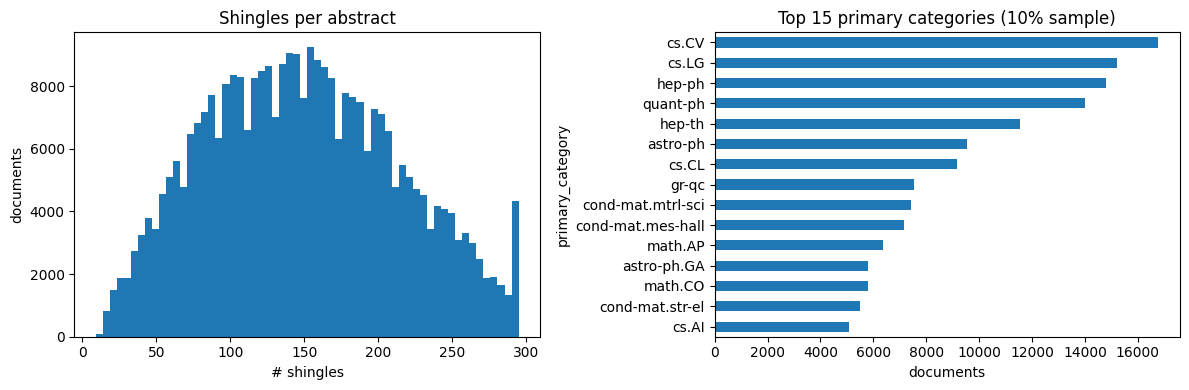

In [8]:
saved = spark.read.parquet(OUT_DIR)

prof = saved.agg(
    F.count("*").alias("rows"),
    F.countDistinct("id").alias("distinct_ids"),
    F.sum((F.col("n_shingles") == 0).cast("int")).alias("zero_vectors"),   # rows with >=1 shingle always have nnz >= 1
    F.sum(F.col("is_synthetic").cast("int")).alias("synthetic_rows"),
    F.avg("n_shingles").alias("avg_shingles"),
    F.expr("percentile_approx(n_shingles, array(0.5, 0.95))").alias("p50_p95"),
    F.countDistinct("primary_category").alias("n_categories"),
).collect()[0].asDict()

# nnz needs a Python UDF, so estimate it on a 1% sample instead of all rows
nnz_udf = F.udf(lambda v: int(v.numNonzeros()), T.IntegerType())
prof["avg_nnz"] = (saved.sample(0.01, SEED).select(nnz_udf("features").alias("nnz"))
                        .agg(F.avg("nnz")).collect()[0][0])

assert prof["rows"] == prof["distinct_ids"], "duplicate ids!"
assert prof["zero_vectors"] == 0, "empty feature vectors would break MinHashLSH"
sparsity = prof["avg_nnz"] / NUM_FEATURES
print(pd.Series({**prof, "density": f"{sparsity:.4%}"}).to_string())

pdf = saved.select("n_shingles", "primary_category").sample(0.1, SEED).toPandas()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(pdf["n_shingles"].clip(upper=pdf["n_shingles"].quantile(0.99)), bins=60)
ax[0].set(title="Shingles per abstract", xlabel="# shingles", ylabel="documents")
pdf["primary_category"].value_counts().head(15)[::-1].plot.barh(ax=ax[1])
ax[1].set(title="Top 15 primary categories (10% sample)", xlabel="documents")
plt.tight_layout(); plt.show()

## 5. Partitioning and caching benchmark (report: optimization section)

Time the shingling + vectorization stage under different partition counts, and with / without `persist()`.
`format("noop")` forces Spark to compute every column without paying for a disk write.

26/11/02 15:30:54 WARN MemoryStore: Not enough space to cache rdd_196_97 in memory! (computed 34.9 MiB so far)
26/11/02 15:30:54 WARN BlockManager: Persisting block rdd_196_97 to disk instead.
26/11/02 15:30:54 WARN MemoryStore: Not enough space to cache rdd_196_99 in memory! (computed 35.0 MiB so far)
26/11/02 15:30:54 WARN BlockManager: Persisting block rdd_196_99 to disk instead.
26/11/02 15:30:56 WARN MemoryStore: Not enough space to cache rdd_196_98 in memory! (computed 67.8 MiB so far)
26/11/02 15:30:56 WARN BlockManager: Persisting block rdd_196_98 to disk instead.
26/11/02 15:31:02 WARN MemoryStore: Failed to reserve initial memory threshold of 1024.0 KiB for computing block rdd_196_100 in memory.
26/11/02 15:31:02 WARN MemoryStore: Not enough space to cache rdd_196_100 in memory! (computed 0.0 B so far)
26/11/02 15:31:02 WARN BlockManager: Persisting block rdd_196_100 to disk instead.
26/11/02 15:31:03 WARN MemoryStore: Failed to reserve initial memory threshold of 1024.0 KiB 

 partitions  seconds
          2   496.92
          4   460.01
          8   452.03
         16   454.01
         32   454.42
         64   456.49

strategy  run  seconds
no cache    1   440.64
no cache    2   436.43
 persist    1   560.91
 persist    2    25.90


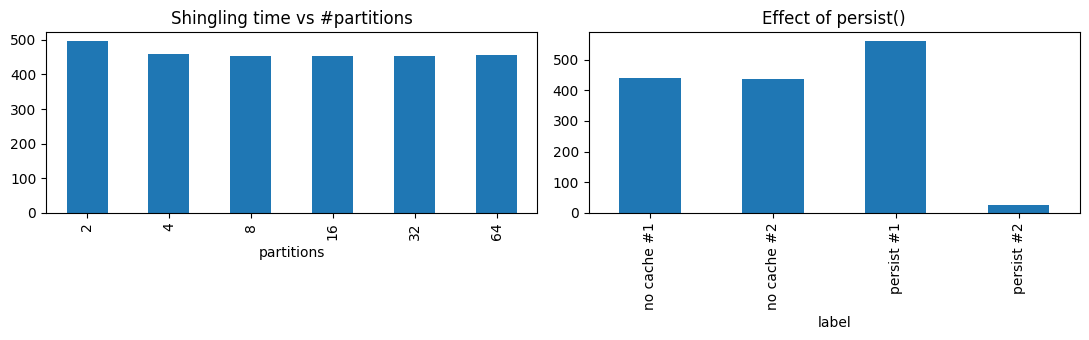

In [9]:
def run_plan(df):
    t0 = time.perf_counter()
    df.write.format("noop").mode("overwrite").save()
    return time.perf_counter() - t0

src = spark.read.parquet(OUT_DIR).select("id", "clean_text")

def pipeline(df, parts):
    return vectorize(shingle_df(df.repartition(parts), K), NUM_FEATURES)

run_plan(pipeline(src, PARTITIONS))          # warm-up (JVM, codegen)

part_df = pd.DataFrame(
    [{"partitions": p, "seconds": round(run_plan(pipeline(src, p)), 2)} for p in [2, 4, 8, 16, 32, 64]])

d_plain = pipeline(src, PARTITIONS)
no_cache = [run_plan(d_plain), run_plan(d_plain)]
d_cached = pipeline(src, PARTITIONS).persist(StorageLevel.MEMORY_AND_DISK)
cached = [run_plan(d_cached), run_plan(d_cached)]
d_cached.unpersist()
cache_df = pd.DataFrame({"strategy": ["no cache", "no cache", "persist", "persist"],
                         "run": [1, 2, 1, 2],
                         "seconds": [round(x, 2) for x in no_cache + cached]})

print(part_df.to_string(index=False)); print(); print(cache_df.to_string(index=False))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
part_df.plot.bar(x="partitions", y="seconds", ax=ax[0], legend=False, title="Shingling time vs #partitions")
cache_df.assign(label=cache_df.strategy + " #" + cache_df.run.astype(str)).plot.bar(
    x="label", y="seconds", ax=ax[1], legend=False, title="Effect of persist()")
plt.tight_layout(); plt.show()

## 6. Choosing the shingle size k

Driver-side experiment on a 2,000-abstract sample (pure Python sets = exact Jaccard).

* **Random pairs** should have near-zero Jaccard for every k; this is the "background" level.
* **Near-duplicate pairs** (an abstract vs. a copy with 5/10/20% of words deleted) lose similarity as k grows,
  because one deleted word destroys k shingles.
* A good k keeps near-duplicates well above random pairs without making them fall below the join threshold.

 k  avg_shingles  random_mean  random_p99  dup_J@5%  dup_J@10%  dup_J@20%
 2      139.4810       0.0087      0.0286    0.8645     0.7502     0.5647
 3      147.0130       0.0006      0.0086    0.7866     0.6275     0.4040
 4      148.2825       0.0001      0.0037    0.7198     0.5328     0.2994
 5      148.0490       0.0000      0.0000    0.6613     0.4566     0.2270


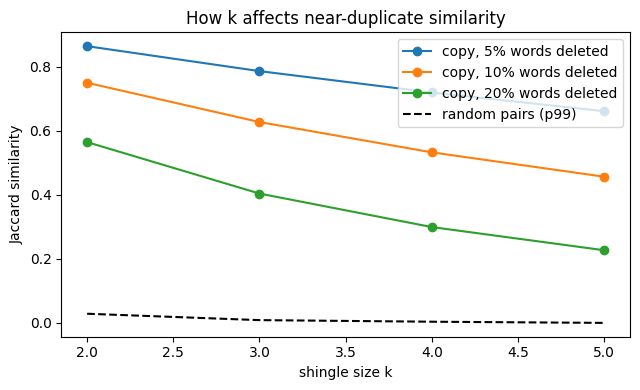

In [10]:
SAMPLE_DOCS    = 2000
N_RANDOM_PAIRS = 20000
DROP_RATES     = [0.05, 0.10, 0.20]
K_LIST         = [2, 3, 4, 5]

sample_docs = (spark.read.parquet(OUT_DIR).filter(~F.col("is_synthetic"))
               .select("id", "clean_text").orderBy(F.xxhash64("id", F.lit(SEED)))
               .limit(SAMPLE_DOCS).toPandas())
texts = sample_docs["clean_text"].tolist()
n_docs = len(texts)

def shingles_py(text, k):
    w = text.split(" ")
    return {" ".join(w[i:i + k]) for i in range(len(w) - k + 1)}

def jaccard(a, b):
    u = len(a | b)
    return len(a & b) / u if u else 0.0

def mutate_py(text, rate, rng):
    kept = [w for w in text.split(" ") if rng.random() >= rate]
    return " ".join(kept) if kept else text

rng = random.Random(SEED)
mutated = {r: [mutate_py(t, r, rng) for t in texts] for r in DROP_RATES}
pairs = []
while len(pairs) < N_RANDOM_PAIRS:
    i, j = rng.randrange(n_docs), rng.randrange(n_docs)
    if i != j:
        pairs.append((i, j))

rows = []
for k in K_LIST:
    sh = [shingles_py(t, k) for t in texts]
    rp = np.array([jaccard(sh[i], sh[j]) for i, j in pairs])
    row = {"k": k,
           "avg_shingles": np.mean([len(s) for s in sh]),
           "random_mean": rp.mean(),
           "random_p99": np.percentile(rp, 99)}
    for r in DROP_RATES:
        row[f"dup_J@{int(r * 100)}%"] = np.mean([jaccard(a, shingles_py(m, k)) for a, m in zip(sh, mutated[r])])
    rows.append(row)

k_df = pd.DataFrame(rows)
print(k_df.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(6.5, 4))
for r in DROP_RATES:
    ax.plot(k_df["k"], k_df[f"dup_J@{int(r * 100)}%"], marker="o", label=f"copy, {int(r * 100)}% words deleted")
ax.plot(k_df["k"], k_df["random_p99"], "k--", label="random pairs (p99)")
ax.set(xlabel="shingle size k", ylabel="Jaccard similarity", title="How k affects near-duplicate similarity")
ax.legend(); plt.tight_layout(); plt.show()

       dup_drop_rate    true_J
count       2000.000  2000.000
mean           0.150     0.544
std            0.086     0.218
min            0.000     0.100
25%            0.076     0.358
50%            0.149     0.510
75%            0.225     0.712
max            0.300     1.000

clones per true-Jaccard bin:
 true_J
(-0.001, 0.2]     25
(0.2, 0.4]       633
(0.4, 0.6]       584
(0.6, 0.8]       454
(0.8, 1.0]       304


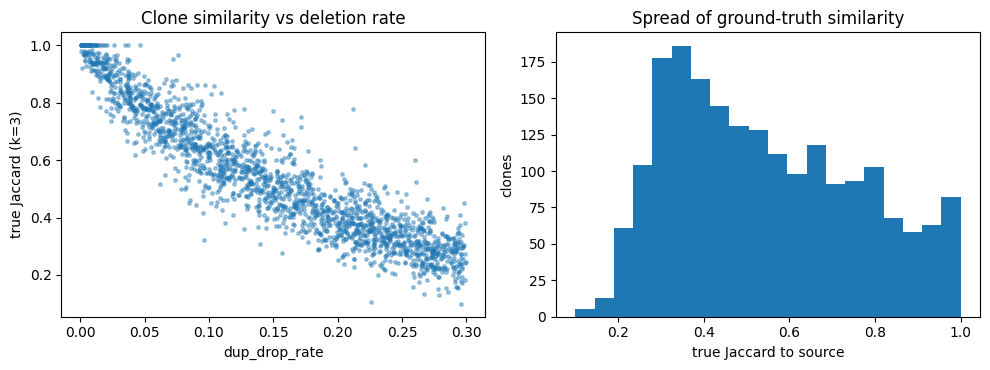

In [11]:
# Verify the synthetic clones: stored deletion rate vs. true Jaccard to the source abstract.
clones = (saved.filter("is_synthetic").select("source_id", "clean_text", "dup_drop_rate")
               .orderBy(F.xxhash64("source_id", F.lit(SEED))).limit(2000))
originals = saved.select(F.col("id").alias("source_id"), F.col("clean_text").alias("src_text"))
cv = clones.join(originals, "source_id").toPandas()

cv["true_J"] = [jaccard(shingles_py(a, K), shingles_py(b, K)) for a, b in zip(cv["src_text"], cv["clean_text"])]
print(cv[["dup_drop_rate", "true_J"]].describe().round(3).to_string())
bins = pd.cut(cv["true_J"], [0, .2, .4, .6, .8, 1.0], include_lowest=True)
print("\nclones per true-Jaccard bin:\n", bins.value_counts().sort_index().to_string())

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].scatter(cv["dup_drop_rate"], cv["true_J"], s=6, alpha=0.4)
ax[0].set(xlabel="dup_drop_rate", ylabel=f"true Jaccard (k={K})", title="Clone similarity vs deletion rate")
ax[1].hist(cv["true_J"], bins=20)
ax[1].set(xlabel="true Jaccard to source", ylabel="clones", title="Spread of ground-truth similarity")
plt.tight_layout(); plt.show()

## 7. Choosing the hash dimension (`numFeatures`)

`HashingTF` maps shingles into `numFeatures` buckets, so different shingles can collide and the Jaccard computed on the
hashed vectors drifts upward. Here we measure that drift with Spark's own `HashingTF` against the exact Jaccard.

 numFeatures     bias  mean_abs_err  pairs
       16384 0.001578      0.002291   1000
       65536 0.000444      0.000724   1000
      262144 0.000118      0.000209   1000
     1048576 0.000017      0.000042   1000


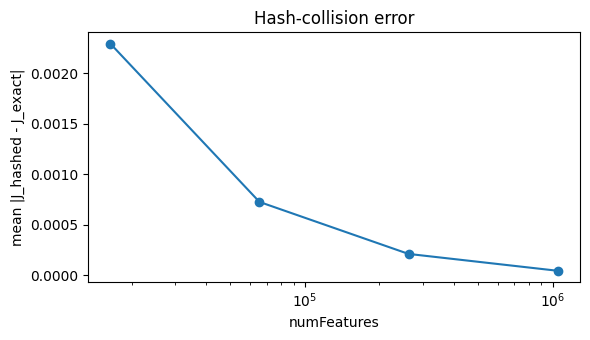

In [12]:
N_PAIRS = min(1000, n_docs)
base_texts, mut_texts = texts[:N_PAIRS], mutated[0.10][:N_PAIRS]
NF_LIST = sorted({1 << 14, 1 << 16, 1 << 18, 1 << 20, NUM_FEATURES})

sdf = spark.createDataFrame(pd.DataFrame({
    "id": [f"{i}_a" for i in range(N_PAIRS)] + [f"{i}_b" for i in range(N_PAIRS)],
    "clean_text": base_texts + mut_texts}))
sh_df = shingle_df(sdf, K)

exact = {i: jaccard(shingles_py(base_texts[i], K), shingles_py(mut_texts[i], K)) for i in range(N_PAIRS)}

res, idx_sets = [], {}
for nf in NF_LIST:
    got = vectorize(sh_df, nf).select("id", "features").collect()
    sets = {r["id"]: set(r["features"].indices.tolist()) for r in got}
    errs = [jaccard(sets[f"{i}_a"], sets[f"{i}_b"]) - exact[i]
            for i in range(N_PAIRS) if f"{i}_a" in sets and f"{i}_b" in sets]
    res.append({"numFeatures": nf, "bias": np.mean(errs), "mean_abs_err": np.mean(np.abs(errs)), "pairs": len(errs)})
    if nf == NUM_FEATURES:
        idx_sets = {i: (sets[f"{i}_a"], sets[f"{i}_b"]) for i in range(N_PAIRS)
                    if f"{i}_a" in sets and f"{i}_b" in sets}

nf_df = pd.DataFrame(res)
print(nf_df.to_string(index=False))
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.semilogx(nf_df["numFeatures"], nf_df["mean_abs_err"], marker="o")
ax.set(xlabel="numFeatures", ylabel="mean |J_hashed - J_exact|", title="Hash-collision error")
plt.tight_layout(); plt.show()

## 8. Seminar demo: MinHash collision probability equals Jaccard

For a random permutation (hash function) `h`: **P[ minhash_h(A) = minhash_h(B) ] = J(A, B)**.
So the fraction of agreeing positions across `H` independent hash functions is an unbiased estimator of `J`
with standard deviation `sqrt(J(1-J)/H)`. We check this on the shingle sets from the previous cell.

H = 128 hash functions | mean abs error = 0.0352 | theoretical std at J=0.5: 0.0442


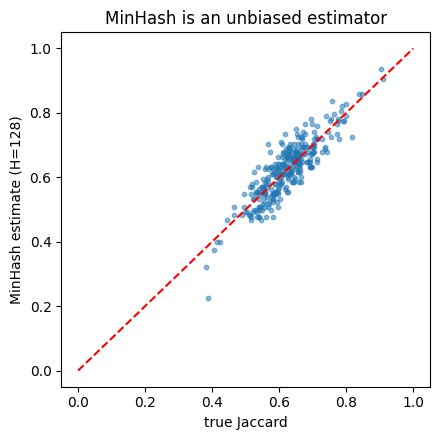

In [13]:
H = 128
P = (1 << 31) - 1                      # prime modulus for universal hashing
rng_np = np.random.default_rng(SEED)
A = rng_np.integers(1, P, size=H, dtype=np.int64)
B = rng_np.integers(0, P, size=H, dtype=np.int64)

def signature(idx_set):
    arr = np.fromiter(idx_set, dtype=np.int64, count=len(idx_set))
    return ((A[:, None] * arr[None, :] + B[:, None]) % P).min(axis=1)

demo = list(idx_sets.values())[:300]
true_j = np.array([jaccard(a, b) for a, b in demo])
est_j = np.array([(signature(a) == signature(b)).mean() for a, b in demo])

print(f"H = {H} hash functions | mean abs error = {np.abs(est_j - true_j).mean():.4f} "
      f"| theoretical std at J=0.5: {np.sqrt(0.25 / H):.4f}")
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.scatter(true_j, est_j, s=10, alpha=0.5)
ax.plot([0, 1], [0, 1], "r--")
ax.set(xlabel="true Jaccard", ylabel=f"MinHash estimate (H={H})", title="MinHash is an unbiased estimator")
plt.tight_layout(); plt.show()

## 9. Slide 2 statistics and hand-off to Members 2 and 3

* Run the final export cell, then save a Kaggle version with outputs. Download `data/processed/arxiv_full_k3/` (the complete Parquet directory, including all part files) and `data/processed/slide2_stats.json` from its Output tab. `/kaggle/temp` is scratch space and is not retained.
* Notebook schema uses `clean_text` and `dup_drop_rate`; `src/preprocess.py` uses `text` and `drop_rate`. Rename these two columns when integrating the notebook artifact with the source pipeline. Both produce binary `features` with k=3, numFeatures=262144 and seed=36.
* Shared seed alone does not make both implementations generate identical clones: the notebook uses pmod with 1,000,000 buckets for the deletion rate; the source uses abs/mod with 10,000. Members 2 and 3 must use the same exported artifact for comparable results.
* `n_shingles` here counts shingle occurrences; the source pipeline deduplicates shingles before counting. Binary HashingTF still represents set membership in both cases.
* Saved outputs were produced with Spark 4.0.4 / Python 3.13.15. The repository currently requires pyspark<4.0; compatibility with that environment has not been verified. Record the actual Spark and Python versions for every new benchmark run.
* The partition/cache benchmark is local execution on 4 CPU cores. It measures local partitioning and reuse, not multi-node cluster speedup. The MinHash demo still uses 10%-deletion pairs; section 6 separately verifies the broader clone similarity distribution.


In [14]:
stats = {
    "source": "Cornell-University/arxiv (Kaggle), arxiv-metadata-oai-snapshot.json",
    "raw_json_gb": round(raw_size_gb, 2),
    "raw_rows": n_raw,
    "after_cleaning": n_clean,
    "after_exact_dedup": n_dedup,
    "tier_rows_before_injection": n_tier,
    "final_rows": prof["rows"],
    "synthetic_near_duplicates": prof["synthetic_rows"],
    "dup_drop_max": DUP_DROP_MAX,
    "shingle_size_k": K,
    "num_features": NUM_FEATURES,
    "avg_shingles_per_doc": round(prof["avg_shingles"], 1),
    "p50_p95_shingles": [int(x) for x in prof["p50_p95"]],
    "avg_nonzeros_per_vector": round(prof["avg_nnz"], 1),
    "vector_density": round(sparsity, 6),
    "n_primary_categories": prof["n_categories"],
    "raw_parquet_mb": round(raw_parquet_mb),
    "output_parquet_mb": round(out_parquet_mb),
    "json_to_parquet_secs": None if ingest_secs is None else round(ingest_secs, 1),
    "partitions": PARTITIONS,
    "seed": SEED,
    "output_path": OUT_DIR,
}
os.makedirs(f"{WORK}/processed", exist_ok=True)
STATS_PATH = f"{WORK}/processed/slide2_stats.json"
with open(STATS_PATH, "w") as f:
    json.dump(stats, f, indent=2)
print(pd.Series(stats).to_frame("value").to_string())

print("\nSchema for Members 2 and 3:")
saved.printSchema()
saved.drop("features", "clean_text").show(5, truncate=40)

                                                                                          value
source                      Cornell-University/arxiv (Kaggle), arxiv-metadata-oai-snapshot.json
raw_json_gb                                                                                5.67
raw_rows                                                                                3233620
after_cleaning                                                                          3224873
after_exact_dedup                                                                       3223098
tier_rows_before_injection                                                              3223098
final_rows                                                                              3255196
synthetic_near_duplicates                                                                 32098
dup_drop_max                                                                                0.3
shingle_size_k                          

In [15]:
# Kaggle keeps only /kaggle/working as notebook output (saved on "Save Version" -> Output tab).
# Scratch data in /kaggle/temp is discarded, so copy the final Parquet + stats here.
SAVE_DIR = "/kaggle/working/data/processed"

os.makedirs(SAVE_DIR, exist_ok=True)
dst = os.path.join(SAVE_DIR, os.path.basename(OUT_DIR))
shutil.copytree(OUT_DIR, dst, dirs_exist_ok=True)
shutil.copy(STATS_PATH, SAVE_DIR)
print(f"Saved to {SAVE_DIR}  ({dir_size_mb(SAVE_DIR):,.0f} MB; Kaggle output limit is 20 GB)")
print(sorted(os.listdir(SAVE_DIR)))

Saved to /kaggle/working/data/processed  (3,721 MB; Kaggle output limit is 20 GB)
['arxiv_full_k3', 'slide2_stats.json']
